In [4]:
# Run simulation

from pathlib import Path
from ior2ecl import runsim

home = Path.home()
cop = Path('/home/shared/owner/CoP_files')
#root = cop/'input/CF6_IORSIM_AH/CF6_IORSIM'
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
#root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT_restart_8659_65641526'
iorexe = home/'github/IORSim/build/bin/IORSimX'

# IX
runsim(root=root, iorexe=iorexe, only_host=True, intersect=1, nproc=20, nice=19);
# IX + IORSim
#runsim(root=root, time=None, iorexe=iorexe, nproc=20, nice=19, only_iorsim=False, intersect=1, tandem=True, del_tandem=True, verbose=2, merge=True);
# IORSim
#runsim(root=root, time=None, iorexe=iorexe, only_iorsim=True, intersect=1, tandem=True, del_tandem=True, verbose=2, merge=True);


    Case      : IORSIM_BASECASE_INPUT
    Mode      : Intersect
    Days      : 18812.0
    Run-dir   : /home/AD.NORCERESEARCH.NO/javi/github/IORSim_GUI
    Case-dir  : /home/shared/owner/CoP_files/input/IORSIM_BASECASE_SURF_RES
    Log-files : /home/shared/owner/CoP_files/input/IORSIM_BASECASE_SURF_RES/intersect.log
              : /home/shared/owner/CoP_files/input/IORSIM_BASECASE_SURF_RES/ior2ecl.log
    Version   : 3.7.3
    Started   : 2025-02-18 17:43:51


   Simulation cancelled                                                            ersect)  



In [1]:
# Define read- and plot-functions

from collections import namedtuple
from datetime import datetime
from operator import attrgetter
from pathlib import Path
from itertools import repeat
import matplotlib.pyplot as pl
from numpy import array, flipud, frompyfunc, nan, ones, where
from pandas import read_excel
#from IORlib.ECL import UNRST_file
from IORlib.utils import batched, ceildiv, first_index, groupby_sorted, ppm2molL


#--------------------------------------------------------------------------------
def figures(*keywords, ncols=1, size=(8, 4), wspace=0.25):
#--------------------------------------------------------------------------------
    # Create figure and axes
    pl.close('all')
    nplots = len(keywords)
    nrows = ceildiv(nplots, ncols)
    fig = pl.figure(figsize=(size[0]*ncols, size[1]*nrows))
    axes = {key:fig.add_subplot(nrows, ncols, i+1) for i,key in enumerate(keywords)}
    fig.subplots_adjust(bottom=0.05, top=0.88, hspace=0.3, wspace=wspace)
    return fig, axes

#--------------------------------------------------------------------------------
def save(ax, fig, path, dpi=300):
#--------------------------------------------------------------------------------
    # Save individual plots
    extent = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
    pl.savefig(path, bbox_inches=extent.expanded(1.3, 1.4), dpi=dpi)

#--------------------------------------------------------------------------------
def date(values):
#--------------------------------------------------------------------------------
    return datetime.strptime('-'.join(map(str, values)), '%d-%b-%Y')

#--------------------------------------------------------------------------------
def read_hist_prod(root):
#--------------------------------------------------------------------------------
    # Read historical cumulative production 
    names, eko_cuml = read_obsh(root)
    data = {well:array(cuml) for well,cuml in groupby_sorted(eko_cuml)}
    # Get property 'days' from array of timedelta objects 
    days = frompyfunc(attrgetter('days'), 1, 1)
    # Calculate rate per day from cumulative data
    well_rates = ((well, (cuml[1:,1:-2]-cuml[:-1,1:-2])/days(cuml[1:,0]-cuml[:-1,0])[:, None]) for well, cuml in data.items())
    # Find index gas, oil, water index in the data matrix
    rate_index = {name.replace('_CUML', '').lower():i for i,name in enumerate(names[2:-2])}
    gas, oil, wat = [rate_index[f'{phase}_production'] for phase in ('gas', 'oil', 'water')]
    # Return a namedtuple for each well
    rate_tuple = namedtuple('Rates', 'gas oil water')
    well_rate_tuples = {well: rate_tuple(*[rate[:,ph] for ph in (gas, oil, wat)]) for well,rate in well_rates}
    well_dates = {w:d[1:,0] for w,d in data.items()}
    return namedtuple('Welldata', 'dates rates')(well_dates, well_rate_tuples)
    #return namedtuple('Eko_data', 'dates rates index')({w:d[1:,0] for w,d in data.items()}, rate, rate_index)

#--------------------------------------------------------------------------------
def read_obsh(root:Path):
#--------------------------------------------------------------------------------
    with open(root.with_suffix('.obsh')) as file:
        header = next(batched(file, 4))
        names = header[-1].split()
        first_line = next(file).split()
        ncol = len(first_line)
        lines = batched(first_line+''.join(file).split(), ncol)
        data = ((l[0], datetime.strptime('-'.join(l[1:4]),'%d-%b-%Y'), *map(float, l[4:])) for l in lines)
        return names, data

#--------------------------------------------------------------------------------
def find_specie(name, species):
#--------------------------------------------------------------------------------
    return next((s for s in species if s.upper()==name), None)

#--------------------------------------------------------------------------------
def read_ion_data(well, xls, species, unit='ppm'):
#--------------------------------------------------------------------------------
    if not well in xls.sheet_names:
        return ()
    # Read measured data from excel
    xls_sheet = read_excel(xls, sheet_name=well)
    # In the Excel-file, data is ordered by decreasing date, but we want old dates first
    xls_data = flipud(xls_sheet.to_numpy())
    ion_dates = xls_data[:,3]
    mark_datapoint = nan*ones(ion_dates.shape)
    if preserved_cd := first_index(lambda x: x == 'PRESERVED CD', xls_sheet.columns):
        # Do not plot if string is given, i.e. set to nan for strings
        good_data = array([isinstance(d, str) for d in xls_data[:, preserved_cd]])
        mark_datapoint[where(good_data==False)] = 1
    specie_ind = ((specie, i) for i,name in enumerate(xls_sheet.columns) if (specie:=find_specie(name, species)))
    convert = lambda x: 1
    if unit=='molL':
       convert = lambda x: ppm2molL(x)
    ion_data = {specie:xls_data[:,i]*convert(specie) for specie, i in specie_ind}
    return namedtuple('Ions', 'dates data no_scale')(ion_dates, ion_data, mark_datapoint)
    #ion_dates, ion_data, mark_datapoint

#--------------------------------------------------------------------------------
def plot(ax, x, y, *args, begin=None, end=None, log=False, **kwargs):
#--------------------------------------------------------------------------------
    a, b = [first_index(lambda d:d > date, x) for date in (begin, end)]
    if log:
        return ax.semilogy(x[a:b], y[a:b], *args, **kwargs)
    return ax.plot(x[a:b], y[a:b], *args, **kwargs)

#--------------------------------------------------------------------------------
def plot_production(ax, well, eko_data, ix_sim:tuple, units=None, show=None, **kwargs):
#--------------------------------------------------------------------------------
    handles = []
    def pplot(*args, **kwargs):
        handle, = plot(*args, **kwargs)
        handles.append(handle)
    
    lines = ('-', '--', '-.', ':')
    # Plot production
    ax.set_title('Production')
    # Plot simulated production
    if show.gas:
        # Right axis for gas rate
        ax2 = ax.twinx()
        for sim, line in zip(ix_sim, lines):
            pplot(ax2, sim.dates, getattr(sim.WGPR, well),
                    line+'g', label='Simulated gas', alpha=1, **kwargs)
    if show.oil:
        for sim, line in zip(ix_sim, lines):
            pplot(ax, sim.dates, getattr(sim.WOPR, well),
                    line+'r', label='Simulated oil', alpha=0.25, **kwargs)
    for sim, line in zip(ix_sim, lines):
            pplot(ax, sim.dates, getattr(sim.WWPR, well),
                    line+'b', label='Simulated water', alpha=0.5, **kwargs)
    # Plot real production
    if show.gas:
        pplot(ax, eko_data.dates[well], eko_data.rates[well].gas, 
                    'oy', label='Produced gas', mec='None', alpha=0.5, **kwargs)
    if show.oil:
        pplot(ax, eko_data.dates[well], eko_data.rates[well].oil,
                    'om', label='Produced rate', mfc='None', alpha=0.25, **kwargs)
    pplot(ax, eko_data.dates[well], eko_data.rates[well].water,
                'oc', label='Produced water', mec='None', alpha=0.75, **kwargs)
    ax.set_xlabel('Year')
    if units:
        ax.set_ylabel(f'{units.WOPR.measure} [{units.WOPR.unit}]')
    if show.gas:
        ax2.set_ylabel(f'{units.WGPR.measure} [{units.WGPR.unit}]')
    ax.legend(handles=handles, loc='upper center', ncols=2)


In [2]:
# Plot production and concentration for all wells

from dataclasses import dataclass
from datetime import timedelta
from pathlib import Path
from matplotlib.pyplot import semilogy
from pandas import ExcelFile
from IORlib.utils import molL2ppm
from IORlib.ECL import UNSMRY_file
from ior2ecl import IORSim_input, IORSim_output
from pypdf import PdfWriter

skip = ('B05T2', 'B09B', 'B19BT2', 'C08T2', 'M13')
unit = 'ppm' #'molL' #'ppm'
tag = '_chem_compare'

@dataclass
class show:
    gas = False
    oil = False
    data = True
    dissolution = False
    temp = True

only_wells_with_data = True

cop = Path('/home/shared/owner/CoP_files')
root = cop/'output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
#root2 = cop/'input/IORSIM_BASECASE_INCOMP/IORSIM_BASECASE_INPUT'
root2 = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'

before = timedelta(days=1*365)
after = timedelta(days=365)
species = ('Cl', 'Ca', 'Mg', 'Ba', 'SO4')

%matplotlib widget 

unsmry = UNSMRY_file(root)
unsmry2 = UNSMRY_file(root2)
xls = ExcelFile(cop/'ionedata/ions_ekofisk_all_v2.xlsx')
prod_data = read_hist_prod(root)
inj_conc = IORSim_input(root).solutions()

if only_wells_with_data:
    wells = xls.sheet_names
else:
    wells = IORSim_input(root2).wells().prod

pdf_files = []

#wells = ['B01A'] #, 'X06']
for well in wells[:]:
    print(f'\r{well}: ', end='')
    if well in skip:
        print(' SKIP!')
        continue

    # Read IORSim data
    ior = IORSim_output(root)
    ior2 = IORSim_output(root2)
    ior_no_chem = ior2.welldata(well, path='iorsim_data_wellfix_no_rates', raise_error=False)
    #ior_chem = ior_data(root, well, ior_folder='iorsim_data_chem')
    if not ior_no_chem:
        print(' NO DATA!')
        continue
    # cop_data_cf6 = ior.welldata(well, path='iorsim_data_cf6_rate') 
    # cop_data_ionex = ior.welldata(well, path='iorsim_data_ionex') 
    #ior_torfix = ior.welldata(well) #, path='iorsim_data_felix') 
    #ior_current = ior.welldata(well, path='iorsim_data_felix') 
    #ior_current2 = ior2.welldata(well) 
    #ior_resrate_chem = ior2.welldata(well, path='iorsim_data_resrate_chem') 
    #ior_surfrate_chem = ior2.welldata(well, path='iorsim_data_surfrate_chem') 
    #ior_surfrate_allchem2 = ior2.welldata(well, path='iorsim_data_surfrate_allchem_V2') 
    ior_surfrate_lowmagn = ior2.welldata(well, path='iorsim_data_surfrate_lowmagn') 
    #ior_surfrate_allchem = ior2.welldata(well, path='iorsim_data_surfrate_allchem') 
    #ior_resrate_nochem = ior2.welldata(well, path='iorsim_data_OKresrate_NOchem') 
    #ior_WRONG_resrate = ior2.welldata(well, path='iorsim_data_WRONGresrate_NOchem') 
    # ior_chem = ior2.welldata(well) #, path='iorsim_data_wellfix_no_rates')
    #ior_surf_not        = ior2.welldata(well, path='iorsim_data_no_chem')
    # ior_surf_not_corr   = ior2.welldata(well, path='iorsim_data_no_chem_corr')
    #ior_surf            = ior2.welldata(well, path='iorsim_data_min_kinet')
    # ior_surf_corr       = ior2.welldata(well, path='iorsim_data_min_kinet_corr')
    # ior_res_not_corr    = ior2.welldata(well, path='iorsim_data_resrate_nochem')
    # ior_res_not_corr_v2 = ior.welldata(well, path='iorsim_data_nochem')
    #ior_wellfix         = ior2.welldata(well, path='iorsim_data_wellfix_aksel_rates')
    # ior_wellfix_2       = ior2.welldata(well, path='iorsim_data_wellfix_no_rates')


    ion = ()
    if show.data:
        # Read measured ion conc. for given well from excel-sheet
        ion = read_ion_data(well, xls, species, unit=unit)

    # Set begin and end dates for the plots
    # if ion:
    #     begin = ion.dates[0] - before
    #     end = ion.dates[-1] + after
    # else:
    dates = prod_data.dates[well]
    begin = dates[0] - before
    end = dates[-1] + after

    # Prepare plots
    pl.close('all')
    plots = ('prod', *species) + (('diff',) if show.dissolution else ())
    fig, axes = figures(*plots, ncols=2, size=(7,4), wspace=0.3)
    #fig, axes = figures('prod', *species, 'diff', ncols=2, size=(7,4), wspace=0.3)
    fig.suptitle(well)

    # Read and plot production data for the given well
    prodkeys = ('WOPR', 'WWPR')
    if show.gas:
        prodkeys += ('WGPR',)
    ix_sim = unsmry.welldata(keys=prodkeys, wells=(well,), named=True)
    ix_sim2 = unsmry2.welldata(keys=prodkeys, wells=(well,), named=True)
    ax = axes['prod']
    plot_production(ax, well, prod_data, (ix_sim,), units=unsmry.key_units(), show=show, begin=begin, end=end)
    save(ax, fig, cop/'ionedata/X6_prod_rates.png')

    # Plot species
    handles = []
    label_list = []
    convert = lambda x: 1
    unit_str = 'mol/L'
    if unit=='ppm':
        convert = lambda x: molL2ppm(x)
        unit_str = 'ppm'

    def add_handle(p, **kwargs):
        if (label:=kwargs.get('label')) and label not in label_list:
            handles.append(p)
            label_list.append(label)

    def plot_specie(ax, specie, data, *args, **kwargs):
        p, = plot(ax, data.dates, convert(specie)*array(data.conc[specie.upper()]), *args, begin=begin, end=end, alpha=0.7, **kwargs)
        add_handle(p, **kwargs)
        return p

    def plot_measured_ions(ax, *args, **kwargs):
        p, = ax.plot(ion.dates, *args, **kwargs)
        add_handle(p, **kwargs)
        return p

    def plot_inj_conc(ax, sol, col, specie, x, ylim, pos=20):
        conc = convert(specie)*inj_conc[sol][specie]*ones(2)
        dy = ylim[1] - ylim[0]
        ax.text(x[-min(pos, len(x))], conc[0]+0.01*dy, sol, fontsize=10, alpha=0.4, color=col)
        ax.plot((x[0], x[-1]), conc, col+'-', lw=2, alpha=0.2)

    for specie, ax in list(axes.items())[1:1+len(species)]:
        # Species
        ax.set_title(specie)
        ax.set_xlabel('Year')
        ax.set_ylabel(f'Conc. [{unit_str}]')
        p = plot_specie(ax, specie, ior_no_chem, ls='--', label='No chemistry')
        #plot_specie(ax, specie, ior_resrate_nochem, ls=':', label='No chemistry, resrate')
        #plot_specie(ax, specie, ior_surfrate_chem, label='Mineral kinetics')
        #plot_specie(ax, specie, ior_surfrate_allchem2, label='Min. kin. + ion ex. + surf. compl.')
        plot_specie(ax, specie, ior_surfrate_lowmagn, label='Low magnesite')
        #plot_specie(ax, specie, ior_current, label='Current')
        #plot_specie(ax, specie, ior_current2, label='Current2')
        #plot_specie(ax, specie, ior_torfix, label='Fix border')
        #plot_specie(ax, specie, cop_data_ionex, label='CoP ionex')
        #plot_specie(ax, specie, cop_data_cf6, label='CoP CF6')
        #plot_specie(ax, specie, ior_resrate_chem, label='Chemistry, resrate')
        #plot_specie(ax, specie, ior_current, label='Current')
        #plot_specie(ax, specie, ior_surf, label='Mineral reactions')
        #plot_specie(ax, specie, ior_resrate, label='Res. rates')
        #plot_specie(ax, specie, ior_WRONG_resrate, label='WRONG res.rate')
        #plot_specie(ax, specie, ior_chem, label='Chemistry')
        #plot_specie(ax, specie, ior_surf_not_corr, label='No chem, with trick')
        #plot_specie(ax, specie, ior_surf_corr, label='Mineral reactions')
        #plot_specie(ax, specie, ior_wellfix_2, 'r-', label='No chem, with wellfix')
        #p5, = plot_specie(ax, specie, ior_res_not_corr, label='Reservoir rates, advection')
        #p6, = plot_specie(ax, specie, ior_res_not_corr_v2, label='Also reservoir rates, advection')
        #p5, = plot_specie(ax, specie, ior_surf_corr_ions, label='Mineral reactions with corr with ions')
    
        # Formation and injection concentrations    
        for sol, col, pos in (('seawater', 'b', 20), ('ekofisk', 'g', 15), ('tor', 'r', 7)):
            plot_inj_conc(ax, sol, col, specie, p.get_xdata(), ax.get_ylim(), pos)
    
        # Temperature on right axis
        if show.temp:
            ax2 = ax.twinx()
            ax2.set_ylabel(r'Temperaure [$\degree C$]')
            p, = plot(ax2, ior_no_chem.dates, ior_no_chem.conc['Temp'], 'r:', alpha=0.3, lw=1.5, label='Temperature', begin=begin, end=end)
            add_handle(p, label='Temp')
        if ion:
            plot_measured_ions(ax, ion.data[specie], 'mo', mec='None', ms=7, alpha=0.2, lw=2, label='Measured')
            plot_measured_ions(ax, ion.no_scale*ion.data[specie], 'k.', ms=3, alpha=0.3, label='No scale inhibitor')
        # Save individual plots
        #save(ax, fig, cop/'ionedata'/f'{well}_{specie}_conc{tag}.png')

    fig.legend(handles=handles, bbox_to_anchor=(.65, 0.95), borderaxespad=0., ncols=4)

    if show.dissolution:
        # Plot difference
        ax = axes['diff']
        ax.set_title('Effect of chemistry: > 0 for dissolution, < 0 for precipitation', fontsize=10)
        lines = []
        with_chem = ior_chem #ior_surf_corr 
        no_chem = ior_no_chem #ior_surf_not_corr
        diff = {}
        for specie in ('Ca', 'Mg', 'SO4', 'HCO3'):
            SPECIE = specie.upper()
            diff[SPECIE] = with_chem.conc[SPECIE] - no_chem.conc[SPECIE]
            l, = plot(ax, with_chem.dates, diff[SPECIE], label=rf'$\Delta$ {specie}', begin=begin, end=end)
            lines.append(l)
        ax.legend(handles=lines, bbox_to_anchor=(.7, 0.95), borderaxespad=0.)
        label = r'$\Delta$Ca + $\Delta$Mg - $\Delta$SO4 - $\Delta$HCO3'
        l1, = plot(ax, with_chem.dates, diff['CA']+diff['MG']-diff['SO4']-diff['HCO3'], label=label, begin=begin, end=end)
        ax.twinx().legend(handles=[l1], bbox_to_anchor=(.7, 0.2), borderaxespad=0.)

    # Save whole plot
    filename = f'ionedata/plots/{well}{('_IONS' if ion else '')}_all{tag}.pdf'
    pdf_files.append(filename)
    pl.savefig(cop/filename, dpi=200)
    print(' Wrote', filename)

# Merge the pdf's 
writer = PdfWriter()
path = Path.home()/'CoP_files'
for pdf in pdf_files:
    writer.append(path/pdf)
pdfname = path/f'ionedata/pdf/plot{tag}.pdf'
writer.write(pdfname)
writer.close()
print(' Wrote', pdfname)


C03:  NO DATA!
C08T2:  SKIP!
C16: 

TypeError: unsupported operand type(s) for +: 'NoneType' and 'datetime.timedelta'

In [ ]:
# Merge nohup runs

from ior2ecl import Output
from pathlib import Path

cop = Path('/home/shared/owner/CoP_files')
root = cop/'output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
#root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'

out = Output(root)
#next(out.ior_unrst.section_blocks())
out.merge(force=True)
#out.slb_unrst.end_date()
#ior_dates = list(out.ior_unrst.dates())
#len(ior_dates), ior_dates[-1]

In [ ]:
# Dict of grid positions with well names

from itertools import product
from pathlib import Path
from IORlib.ECL import RFT_file, IX_input, UNRST_file

cop = Path('/home/shared/owner/CoP_files')
root = cop/'output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'

inp = IX_input(root)
rft = RFT_file(root)
dim = UNRST_file(root).dim()
grid2well = rft.grid2wellname(dim, *inp.wellnames())

# wellpos = {pos:[] for pos in product(*(range(d) for d in dim))}
# #wells = inp.wellnames()
# wellpos = {}
# for well, pos in zip(wells, rft.wellpos(*wells)):
# #for well, pos in rft.wellpos2(*wells):
#     for p in pos:
#         wellpos[p].append(well)

# Check well B13
#wellpos[(93,67,10)]
grid2well[(92,66,9)]

In [6]:
from pathlib import Path
from IORlib.ECL import RFT_file, IX_input, UNRST_file

cop = Path('/home/shared/owner/CoP_files')
root1 = cop/'output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
root2 = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
root = root1

rft = RFT_file(root)
host_unrst = UNRST_file(root)

start = host_unrst.count_sections() - 1 #3
species = ('CL', 'CA', 'MG', 'BA', 'SO4')
celldata = next(host_unrst.cellarray(*species, start=start, stop=start+1))
celldata.date

opos, = rft.wellpos('K09A')



In [8]:
opos

((85, 107, 3),
 (85, 107, 4),
 (85, 107, 5),
 (85, 107, 6),
 (85, 107, 7),
 (85, 107, 8),
 (85, 107, 9),
 (85, 108, 9),
 (85, 108, 10),
 (84, 108, 10),
 (84, 108, 11),
 (84, 108, 12),
 (84, 108, 13),
 (84, 109, 15),
 (84, 109, 16),
 (84, 109, 17),
 (83, 109, 17),
 (83, 109, 18),
 (83, 109, 19),
 (83, 110, 19),
 (83, 110, 20))

In [2]:
from pathlib import Path
from IORlib.ECL import RFT_file, UNRST_file

cop = Path('/home/shared/owner/CoP_files')
root1 = cop/'output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
root2 = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
root = root1

rft = RFT_file(root)
unrst = UNRST_file(root)
#rft.wellpos('C03') #('K09A')
start, = rft.wellstart('K09A')
unrst.section_number(start)

433

In [10]:
k9a_pos = {k:[] for k in range(83, 86)}
for x,*yz in k9a:
    k9a_pos[x].append(yz)

list(zip(*k9a_pos[83]))

[(109, 109, 109, 110, 110), (17, 18, 19, 19, 20)]

438 439
(266, 23)
(266, 23)
(266, 23)
(266, 23)
(266, 23)
(266, 23)
(266, 23)
(266, 23)
(266, 23)
(266, 23)
(266, 23)
(266, 23)
(266, 23)
(266, 23)
(266, 23)
 Wrote /home/shared/owner/CoP_files/output/IORSIM_BASECASE_1971TO2022/plots/Well_K09A_species.pdf


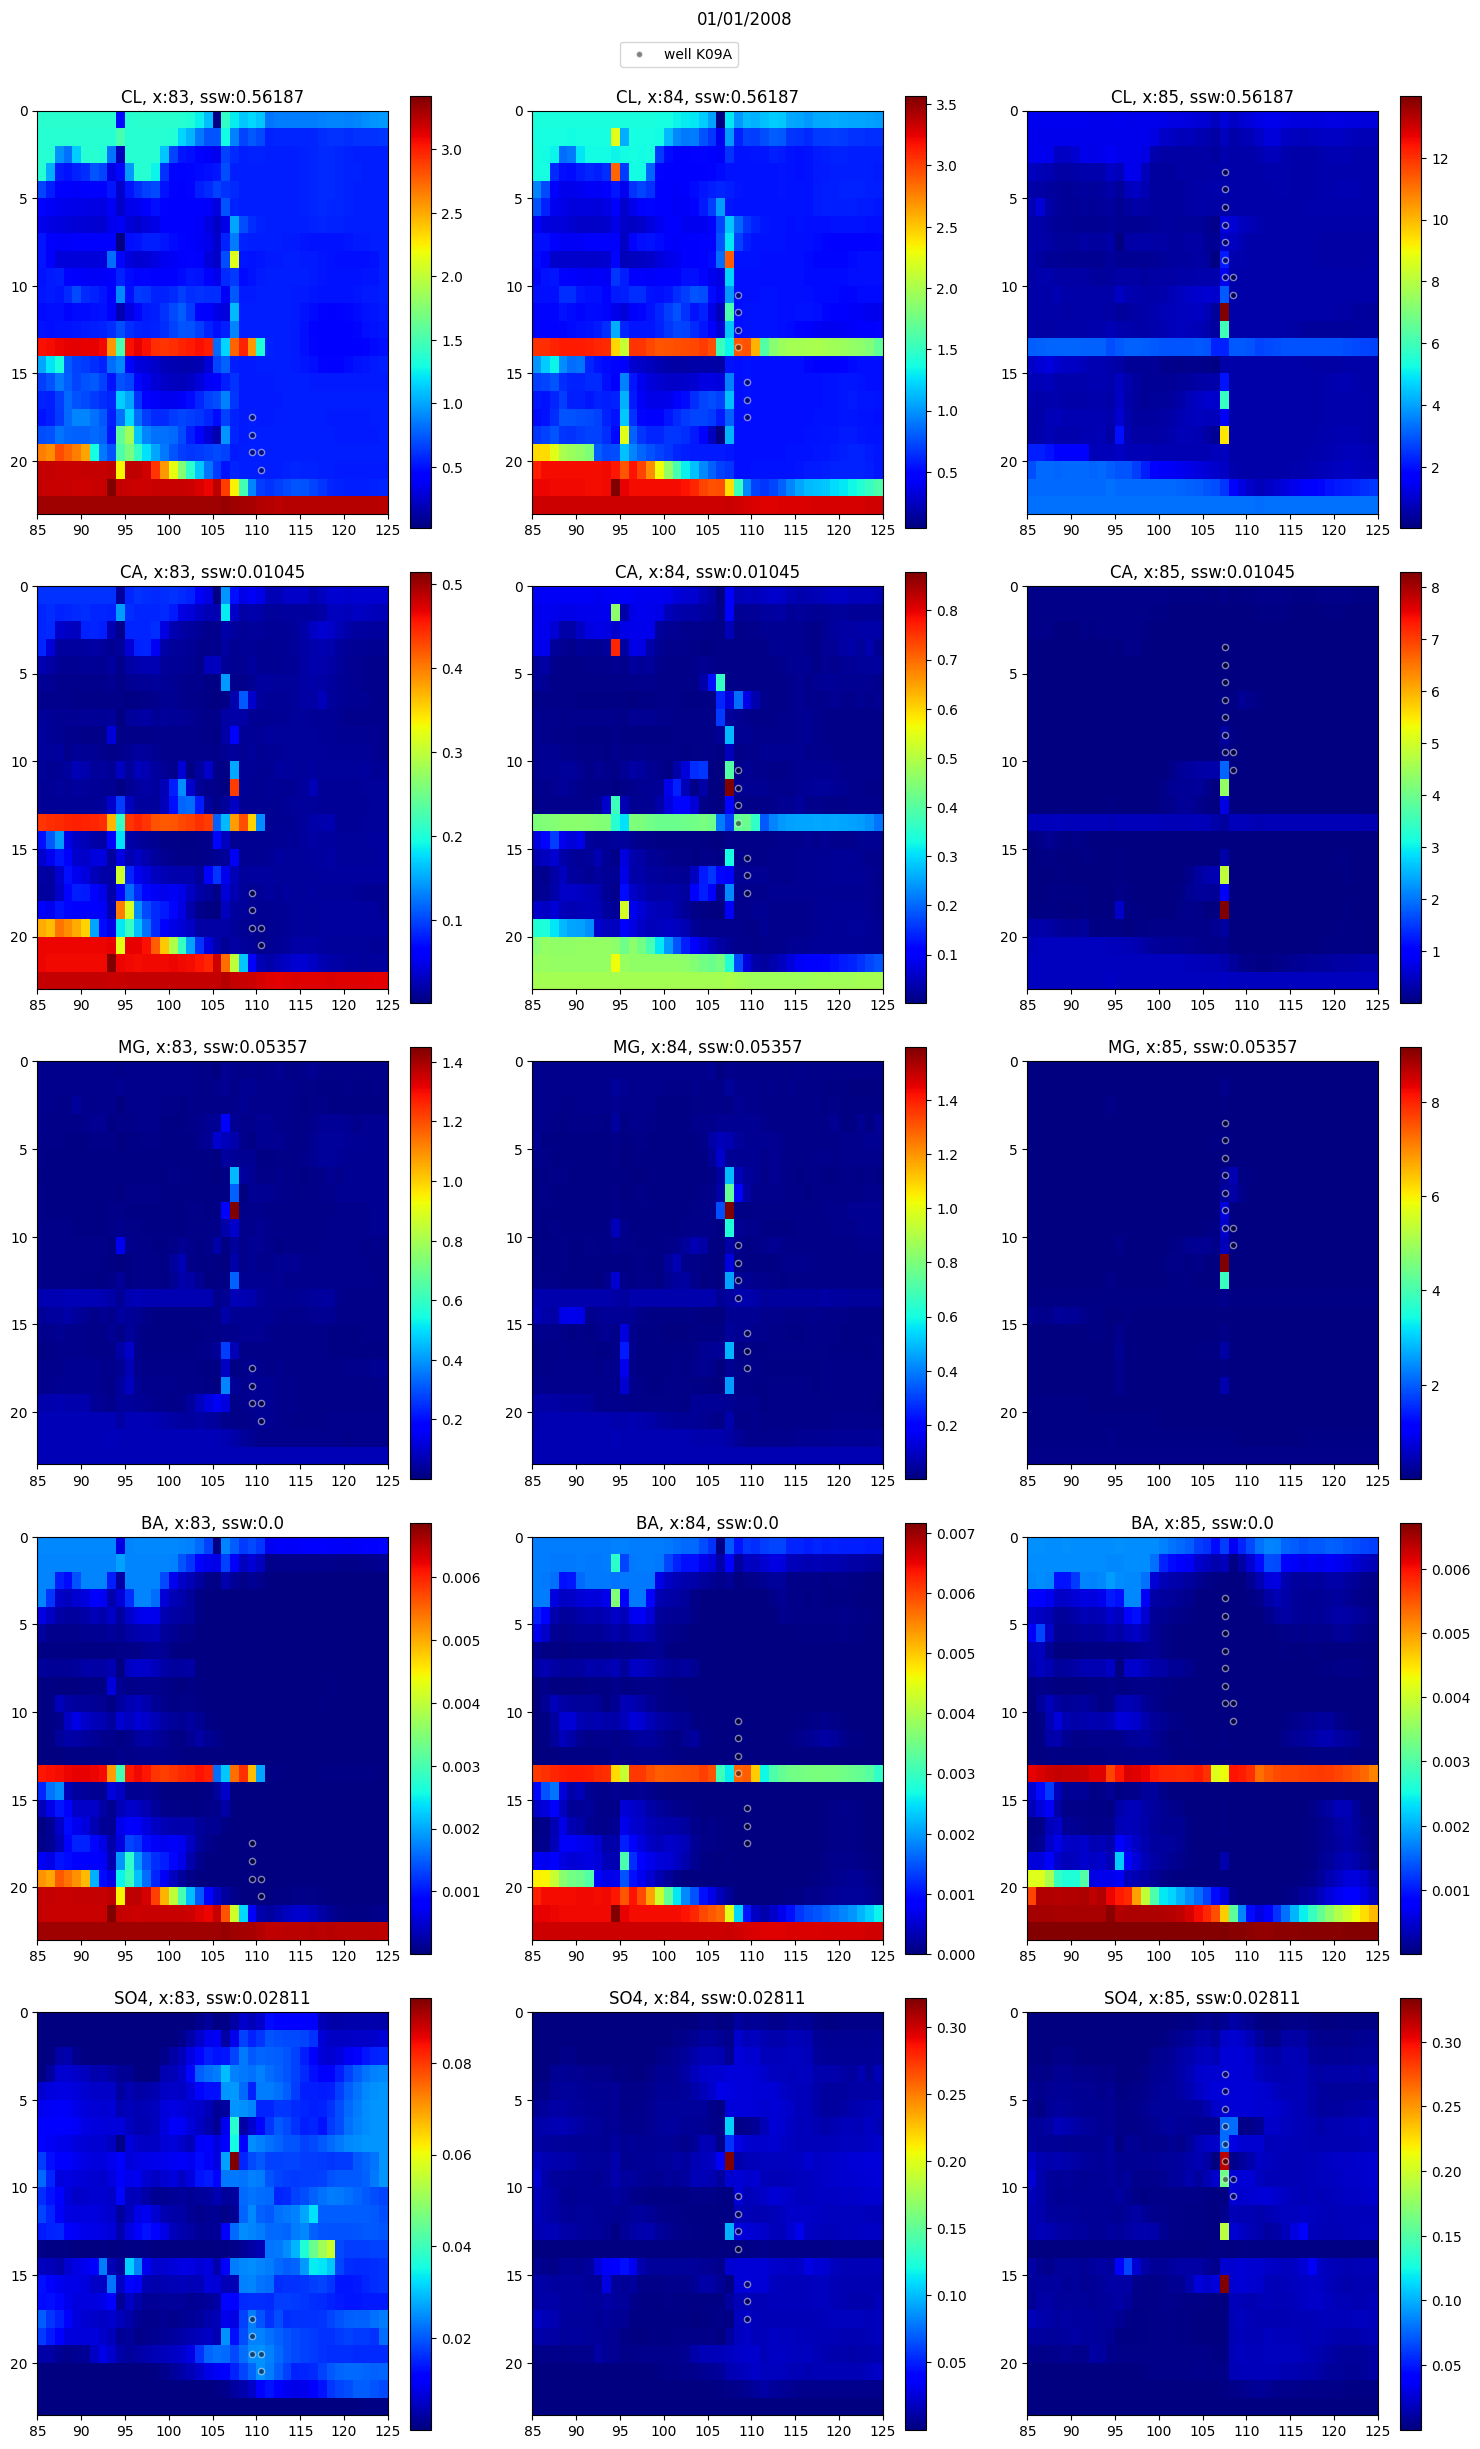

In [21]:
# Plot slice of the reservoir with well positions

from pathlib import Path
import matplotlib.pyplot as pl
from numpy import rot90, arange
from IORlib.ECL import EGRID_file, RFT_file, UNRST_file
from ior2ecl import IORSim_input

%matplotlib inline

egrid = EGRID_file(root)
def resshow(ax, data, xr:slice, yr:slice):

    im = ax.pcolormesh(range(xr.start, xr.stop+1), range(yr.stop, yr.start-1, -1), rot90(data[xr,yr]), cmap='jet')
    ax.invert_yaxis()
    ax.set_aspect(2)
    return im

cop = Path('/home/shared/owner/CoP_files')
root1 = cop/'output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
root2 = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
root = root1


inj_conc = IORSim_input(root).solutions()
ssw = {k.upper():v for k,v in inj_conc['seawater'].items()}

xr = arange(83, 86)
yslice = slice(85,125)
zslice = slice(0,23)

rft = RFT_file(root)
well_pos = {x:[] for x in xr}
well = 'K09A' # 'C03'
wpos, = rft.wellpos(well)
for x,*yz in wpos:
    well_pos[x].append(yz)


host_unrst = UNRST_file(root)
#start = unrst.count_sections() - 1 #3
species = ('CL', 'CA', 'MG', 'BA', 'SO4')

plots = root.parent/'plots'
plots.mkdir(exist_ok=True)
pl.close('all')
#start = host_unrst.section(date=(2022, 1, 1))
days, = rft.wellstart(well)
start = host_unrst.section(days=days)+5
#start = 1
stop = start+1
print(start, stop)
for celldata in host_unrst.cellarray(*species, start=start, stop=stop):
    fig, axes = pl.subplots(len(species), len(xr), figsize=(len(xr)*5, len(species)*5))
    fig.suptitle(celldata.date.strftime('%d/%m/%Y'))
    for rowax, sp in zip(axes, species):
        for ax, x in zip(rowax, xr):
            ax.set_title(f'{sp}, x:{x}, ssw:{ssw[sp]}')
            data = getattr(celldata, sp)[x]
            print(data.shape)
            im = resshow(ax, data, yslice, zslice)
            if well_pos[x]:               
                wy, wz = zip(*well_pos[x])
                ax.scatter([y+0.5 for y in wy], [z+0.5 for z in wz], c='k', s=20, edgecolors='w', alpha=0.5)
            #ax.legend()
            fig.colorbar(im, ax=ax)
    fig.legend(labels=[f'well {well}'], bbox_to_anchor=(0.5, 0.97))
    pl.tight_layout(rect=[0, 0, 1, 0.97]) 
    filepath = plots/f'Well_{well}_species.pdf'
    pl.savefig(filepath, dpi=200)
    print(' Wrote', filepath)


In [34]:
# Get average concentration around a given well

rft = RFT_file(root)
unrst = UNRST_file(root)
ior = IORSim_input(root)

well = 'K09A' # 'C03'
start = unrst.section(date=(2022, 1, 1))
species = ior.species()
celldata = next(unrst.cellarray(*[sp.upper() for sp in species], start=start))

bbox, = rft.wellbbox(well)
xyz = [slice(b[0], b[1]+1) for b in bbox]
inp_sol = {}
for sp in species:
    data = getattr(celldata, sp.upper())[*xyz[:2]]
    inp_sol[sp] = data.mean(axis=(0,1))


In [41]:
# Write solutiion for each layer

for z in range(unrst.dim()[2]):
    print(f' *solution layer{z+1}')
    for sp, conc in inp_sol.items():
        print(f' {sp} {conc[z]:.5e}')
    print()


 *solution layer1
 Ba 1.01132e-03
 Br 2.74964e-03
 Ca 4.91121e-02
 Cl 1.02454e+00
 H 1.01927e+00
 HCO3 2.24005e-02
 K 8.47598e-03
 Mg 3.24418e-02
 Na 8.37117e-01
 SO4 8.59897e-03
 Sr 4.71068e-03

 *solution layer2
 Ba 2.53486e-04
 Br 1.41585e-03
 Ca 2.39487e-02
 Cl 7.26094e-01
 H 1.05586e+00
 HCO3 6.01754e-02
 K 1.06940e-02
 Mg 7.82195e-02
 Na 6.14543e-01
 SO4 1.90406e-02
 Sr 1.25590e-03

 *solution layer3
 Ba 3.74926e-05
 Br 9.89885e-04
 Ca 2.04557e-02
 Cl 6.11444e-01
 H 1.03986e+00
 HCO3 4.34795e-02
 K 1.07859e-02
 Mg 5.84883e-02
 Na 5.25591e-01
 SO4 2.10274e-02
 Sr 2.66495e-04

 *solution layer4
 Ba 1.31759e-06
 Br 8.58746e-04
 Ca 8.70734e-03
 Cl 5.53623e-01
 H 1.00116e+00
 HCO3 6.34412e-03
 K 1.00961e-02
 Mg 3.54866e-02
 Na 4.77387e-01
 SO4 2.56846e-02
 Sr 9.46025e-05

 *solution layer5
 Ba 9.56196e-08
 Br 8.72778e-04
 Ca 8.91207e-03
 Cl 5.63593e-01
 H 1.01243e+00
 HCO3 1.42293e-02
 K 1.02905e-02
 Mg 4.40942e-02
 Na 4.86042e-01
 SO4 2.64270e-02
 Sr 9.07059e-05

 *solution layer6
 B

In [26]:
xy = [slice(b[0], b[1]+1) for b in bbox[:2]]
print(xy)
celldata.CL[*xy].mean(axis=(0,1))

[slice(83, 86, None), slice(107, 111, None)]


array([1.10536663, 0.72506908, 0.56105362, 0.54218573, 0.55327996,
       0.5419933 , 0.815133  , 0.70734764, 0.99868952, 0.66291239,
       0.79649799, 1.79203824, 1.07772172, 2.54546046, 0.53725286,
       0.69809776, 1.03419459, 0.6426014 , 1.31649811, 0.55966666,
       0.57942799, 1.44315468, 3.3052303 ])

In [ ]:
from itertools import product

from IORlib.utils import flatten

def boxpos(pos, dim, xy=2, z=2):
    pos = [tuple(a+b for a,b in zip(p, pos)) for pos in product(range(-xy,xy+1), range(-xy,xy+1), range(-z,z+1))]
    #print('pos', pos)
    return [pp for pp in pos if all(lw <= p <= up for lw,p,up in zip((1,1,1), pp, dim))]

def well_near(pos, dim, dxy=1, dz=1):
    wells = tuple(set(flatten(wp for p in boxpos(pos, dim, dxy, dz) if (wp:=wellpos[p]))))
    #print(wells)
    for well in wells:
        yield well, [p for p,w in wellpos.items() if well in w]

p = (41, 52, 8)
for well, pos in well_near(p, dim):
    print(well, pos)
dim



In [1]:
# Imshow reservoir 
from pathlib import Path
import matplotlib.pyplot as pl
from numpy import rot90, nan as npnan, where
from IORlib.ECL import UNRST_file
from IORlib.utils import ensure_list
#from IORlib.utils import batched, take

#%matplotlib widget
cop = Path('/home/shared/owner/CoP_files')
root1 = cop/'output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
#root1 = cop/'output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022_IORSim_PLOT'
root2 = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'

zpos = 8

pl.close('all')
unrst1 = UNRST_file(root1)
unrst2 = UNRST_file(root2)
#print(unrst1.section_keys())
#vars = ('CL', 'CA', 'MG', 'SO4')
#vars = ('CL',)# 'PRESSURE')
vars = ('CL', 'FLRWATI+', 'FLRWATJ+', 'FLRWATK+')
err_idx = {}
kwargs = dict(start=0*12, stop=1*12, step=1) 
for (day1, date1, *data1),(day2, date2, *data2) in zip(unrst1.cellarray(*vars, **kwargs), unrst2.cellarray(*vars, **kwargs)):
    fig, axes = pl.subplots(1, len(data1), figsize=(8*len(data1), 6))
    axes = ensure_list(axes)
    #fig.suptitle(date1.strftime('%d/%m/%Y'))
    fig.suptitle(f'{day1}, {date1.strftime('%d/%m/%Y')}')
    for d1, d2, ax, var in zip(data1, data2, axes, vars):
        dd = d1-d2
        ax.set_title(f'{var} ({dd.min():.2f}, {dd.max():.2f})')
        # im = ax.imshow(rot90(dd[x,:,::-1]), interpolation='None', origin='upper')
        #if var == 'CL':
        #    err_idx.append(list(zip(*where(dd>3))))
        if var == 'FLRWATI+':
            idx = where(dd>1)
            if pos := list(zip(*idx)):
                #err_idx[int(day1)] = pos
                print(day1, pos)
                # for p in pos:
                #     for well, pp in well_near(p, dim, 1, 1):
                #         print('   ', well)
                #print(f'{day1:.2f}', list(zip(zip(*idx), dd[idx], d1[idx], d2[idx])))
        im = ax.imshow(dd[:60,:60,zpos], interpolation='None', origin='upper')
        fig.colorbar(im, ax=ax)
        #ax.set_aspect(10)


ValueError: The following keywords are missing in IORSIM_BASECASE_INPUT.UNRST: ['CL', 'FLRWATI+', 'FLRWATJ+', 'FLRWATK+']

In [ ]:
#for day, pos in err_idx.items():
#    print(pos)
#    print([list(well_near(p, dim)) for p in pos])
#[w for w in inp.wells() if w[0] in ('B13','K13AT2','K05AT2', 'K01')]

In [ ]:
# Calculate mean values for each layer
from pathlib import Path
import matplotlib.pyplot as pl
from numpy import mean, array
from IORlib.ECL import UNRST_file
from IORlib.utils import ensure_list

def mean_diff_variables(root1, root2, *vars, **kwargs):
    unrst1 = UNRST_file(root1)
    unrst2 = UNRST_file(root2)
    for (day, _, *vals1),(_, _, *vals2) in zip(unrst1.cellarray(*vars, **kwargs), unrst2.cellarray(*vars, **kwargs)):
        yield (day, *[mean(v1-v2, axis=(0,1)) for v1,v2 in zip(vals1, vals2)])

def mean_variables(root, *vars, **kwargs):
    unrst = UNRST_file(root)
    for day, date, *vals in unrst.cellarray(*vars, **kwargs):
        yield (day, *[mean(val, axis=(0,1)) for val in vals])
        
def plot_vars(title, t, vars):
    t = array(t)
    vars = array(vars)
    nvar, ntime, nz = vars.shape
    fig, axes = pl.subplots(1, nvar, figsize=(10*nvar, 6))
    fig.suptitle(title)
    #axes = ensure_list(axes)
    for ax, var, name in zip(axes, vars, varnames):
        ax.set_title(name)
        for i in range(1, nz, 2):
            ax.plot(t/365, var[:,i], label=str(i))
        ax.legend()

cop = Path('/home/shared/owner/CoP_files')
root1 = cop/'output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
root2 = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'

#varnames = ('PRESSURE', 'FLRWATI+', 'FLRWATJ+', 'FLRWATK+', 'CL')
varnames = ('PRESSURE', 'CL')
start = 0
mean_vars = {}
for root in (root1, root2):
    vars = zip(*mean_variables(root, *varnames, start=start))
    mean_vars[root.name] = dict((name, array(var)) for name, var in zip(('days',) + varnames, vars))

#t, *vars = zip(*mean_diff_variables(root1, root2, *varnames, start=start))
#plot_vars('Difference', t, vars)



In [ ]:
# Calculate mean pressure for each layer
import matplotlib.pyplot as pl

%matplotlib widget

pl.close('all')
var1 = mean_vars['IORSIM_BASECASE_1971TO2022']
var2 = mean_vars['IORSIM_BASECASE_INPUT']
a = 15*12
b = 18*12
#pl.figure(figsize=(10,6))
#for l in (0,1,2,3,4,5,8):# range(0,9):
nrow, ncol = 3, 1
# fig = pl.figure(figsize=(ncol*10,nrow*6))
# axes = [fig.add_subplot(, projection='3d' for ij in range(nrow*ncol)]
fig, axes = pl.subplots(nrow, ncol, figsize=(ncol*10,nrow*6)) #, subplot_kw={'projection':'3d'})
for l in (6,7,8,9,10):# range(0,9):
    kwargs = dict(label=f'Layer {l}', alpha=0.7)

    ax = axes[0]#[0]
    ax.set_title('CL for NORCE simulation')
    ax.plot(var2['days'][:]/365, var2['CL'][:,l], **kwargs)
    ax.legend(ncol=2)
    
    ax = axes[1]#[0] 
    ax.set_title('CL for CoP simulation')
    ax.semilogy(var1['days'][:]/365, var1['CL'][:,l], **kwargs)
    ax.legend(ncol=2)
    
    # ax = axes[0][1]
    # ax.set_title('Pressure for CoP simulation')
    # ax.plot(var1['days'][:]/365, var1['PRESSURE'][:,l], label=label)
    # ax.legend(ncol=2)
    
    # ax = axes[1][1]
    # ax.set_title('Pressure for NORCE simulation')
    # ax.plot(var2['days'][:]/365, var2['PRESSURE'][:,l], label=label)
    # ax.legend(ncol=2)

    ax = axes[2]#[0]
    
    b = min(len(var1['days']), len(var2['days']))
    ax.set_title('Pressure difference')
    ax.plot(var2['days'][:b]/365, (var1['PRESSURE'][:b]-var2['PRESSURE'][:b])[:,l], **kwargs)
    ax.legend(ncol=2)

pl.savefig('Compare_simulations.pdf')





In [ ]:
from pathlib import Path
from itertools import zip_longest
from numpy import array
from IORlib.ECL import IX_input, UNRST_file, UNSMRY_file, RFT_file
from ior2ecl import IORSim_input, IORSim_output
from datetime import datetime

cop = Path('/home/shared/owner/CoP_files')
root1 = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
root2 = cop/'output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
#ior = IORSim_output(root)
#unsmry = UNSMRY_file(root)
rft1 = RFT_file(root1)
rft2 = RFT_file(root2)
unrst1 = UNRST_file(root1)
unrst2 = UNRST_file(root2)

#[w for w in IX_input(root1).wellnames() if w[0:2]=='K0']
pos = rft1.wellpos('K09A')
for data in unrst1.cellarray('CL','CA'):
    print(data.CL[tuple(zip(*pos))].shape)
    break
#pos
#keys = ('WELLETC', 'CONIPOS', 'CONJPOS', 'CONKPOS')
#pos = next(d[1:] for d in rft1.blockdata(*keys) if d[0][1]=='B21B')
#list(zip(*pos))
#[f'{d1}, {d2}' for d1, d2 in zip_longest(unrst1.dates(), unrst2.dates())]
    


#keys = ('WELLETC', 'CONWTUB', 'DATE')
#next((d1[-1], d2[-1], array(d1[1])-array(d2[1])) for d1,d2 in zip(rft1.blockdata(*keys), rft2.blockdata(*keys)) if d1[0][1]=='B21B')

#welldata = unsmry.welldata(wells=('B21B',), named=True)
#start = datetime(2006,1,1)
#idx = next((i for i, date in enumerate(welldata.dates) if date > start), None)
#welldata.

#wells = IORSim_input(root).wells().prod
# wells = ['B01A']
# for well in wells:
#     ior_data = ior.welldata(well)
#     ix_data = ix.welldata(keys=('WWPR',), wells=(well,))
#     print(well, len(ix_data.days), len(ior_data.days))
#     #array(ior_data.days) - ix_data.days
# ior_data.days[:100]
# #list(UNRST_file(root).days())

In [ ]:
from IORlib.ECL import IX_input
from ior2ecl import IORSim_output, IORSim_input
from pathlib import Path
import matplotlib.pyplot as pl

cop = Path('/home/shared/owner/CoP_files')
root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
out = IORSim_output(root)
pl.close('all')
for well in IORSim_input(root).wells().prod[:]:
    fix = out.welldata(well, path='iorsim_data_wellfix_aksel_rates')
    no_fix_no_corr = out.welldata(well, path='iorsim_data_no_chem')
    no_fix_corr = out.welldata(well, path='iorsim_data_no_chem_corr')
    pl.figure()
    pl.title(well)
    pl.plot(fix.dates, fix.conc['CL'], 'r-', alpha=1, label='wellfix')
    pl.plot(no_fix_no_corr.dates, no_fix_no_corr.conc['CL'], 'g-', alpha=0.5, label='no correction')
    pl.plot(no_fix_corr.dates, no_fix_corr.conc['CL'], 'b-', alpha=0.5, label='correction')
    pl.legend()


In [ ]:
#
# Write X6 data to an excel-file
#
from numpy import genfromtxt
from datetime import timedelta, datetime
from pathlib import Path
from pandas import DataFrame, ExcelWriter
from itertools import repeat

cop = Path('/home/shared/owner/CoP_files')
wells = ("days", "Ca", "Na", "Cl", "Mg", "SO4", "K", "Ba", "Sr")
ion_data = genfromtxt(cop/'ionedata/well06_1.dat', skip_header=1, names=wells)
# Convert to ppm to be consistent with other measurements 
for specie in wells[1:]:
    ion_data[specie] *= molL2ppm(specie)
data = DataFrame(ion_data)
# Add sample date
start = datetime(1999, 11, 6)
dates = [start+timedelta(days=d) for d in ion_data['days']]
#data.insert(0, 'SAMPLE DATE', [d.strftime('%d.%m.%Y') for d in dates])
data.insert(0, 'SAMPLE DATE', dates)
# Add plant and well information
well = ('PLANT CD', 'WELL ID', 'WELL UWI')[::-1]
var =  ('EKOX'    , '2/4X-06', '2/4-X-6' )[::-1]
for n,v in zip(well, var):
    data.insert(0, n, list(repeat(v, 112)))
# Change column names to uppercase
data = data.rename(columns={name:name.upper() for name in data.columns})
#xlsx = ExcelWriter('ions_X06_JLV.xlsx', datetime_format=)
data.to_excel('ions_X06_JLV.xlsx')